In [1]:
import pandas as pd

df = pd.read_csv("train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)
print()
print(df["SalePrice"].describe())

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [3]:
# 1. Empty means "the house doesn't have this" -> fill with "None"
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType",
             "FireplaceQu", "GarageType", "GarageFinish", "GarageQual",
             "GarageCond", "BsmtExposure", "BsmtFinType2", "BsmtQual",
             "BsmtCond", "BsmtFinType1"]
df[none_cols] = df[none_cols].fillna("None")

# 2. Numbers: no garage or no veneer -> 0
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# 3. Lot frontage: use the typical (median) value
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

# 4. Electrical: one row, use the most common value
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


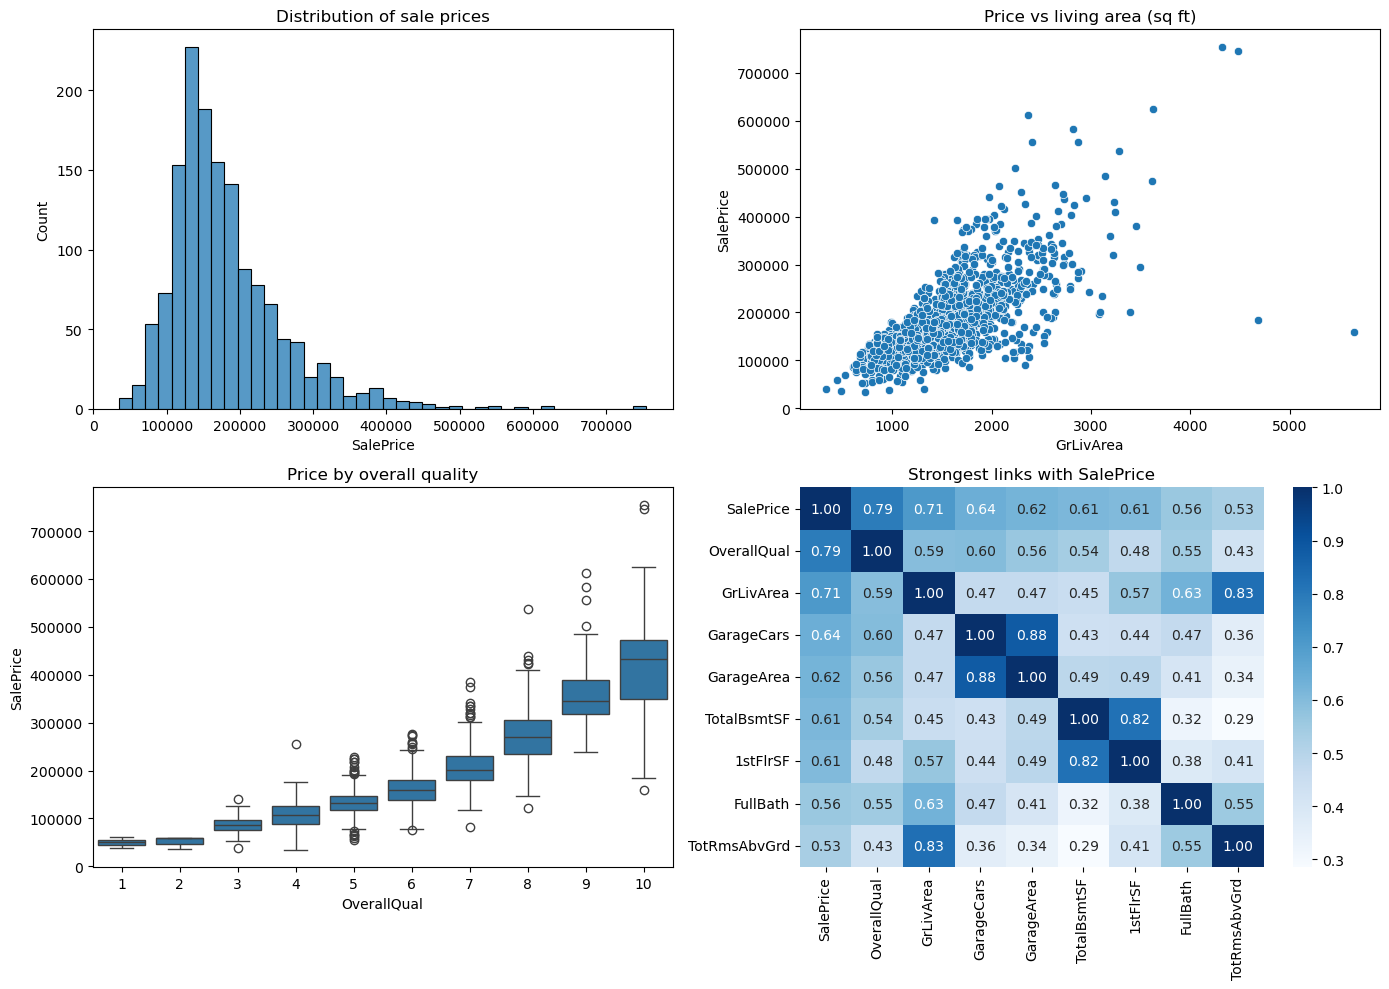

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. How prices are spread
sns.histplot(df["SalePrice"], bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of sale prices")

# 2. Price vs living area
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Price vs living area (sq ft)")

# 3. Price by overall quality (1 to 10)
sns.boxplot(x="OverallQual", y="SalePrice", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Price by overall quality")

# 4. The 8 columns most linked to price
top = df.corr(numeric_only=True)["SalePrice"].abs().sort_values(ascending=False).head(9).index
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="Blues", ax=axes[1, 1])
axes[1, 1].set_title("Strongest links with SalePrice")

plt.tight_layout()
plt.show()

Prices: most houses sell between 100,000 and 250,000 and a few expensive ones stretch the right side.
Living area: bigger houses cost more, but two houses over 4,000 sq ft sold cheaply. They look like outliers, so we remove them.
Quality: price rises steadily with overall quality, from 1 to 10.
Strongest links: overall quality (0.79) and living area (0.71) are the two features most linked to price.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# remove the 2 outliers
df = df[df["GrLivArea"] < 4000]

# turn text columns into numbers, then split into train and test
X = pd.get_dummies(df.drop(columns=["Id", "SalePrice"]))
y = df["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name}: RMSE = ${rmse:,.0f}, R² = {r2_score(y_test, pred):.3f}")

Linear Regression: RMSE = $23,153, R² = 0.898
Decision Tree: RMSE = $40,563, R² = 0.686


Linear Regression gave the best result (RMSE $ 23,153, R² 0.898), better than the Decision Tree (RMSE $40,563, R² 0.686). I used a single 80/20 split and did not tune the tree, so these numbers are a first result, not a final one.